<a href="https://colab.research.google.com/github/khalilinsights/Sales-5444/blob/main/Sales_5444.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             silhouette_samples)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = "Sales-5444.csv"
FIG_DIR = "figures/"
results = {}
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig_name):
    plt.tight_layout()
    plt.savefig(FIG_DIR + fig_name, dpi=200, bbox_inches="tight")
    plt.show()

In [3]:
df = pd.read_csv("Sales-[5444].csv", encoding="utf-8-sig")
df = df.rename(columns={"Item_Name": "brand", "Catatory": "category_raw",
                        "itemLocation": "location"})
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
results["raw_shape"] = df.shape
results["missing_raw"] = df.isna().sum().to_dict()

(1000, 10)
brand                 object
details               object
category_raw          object
price                float64
priceWithCurrency     object
available            float64
text                  object
sold                 float64
lastUpdated           object
location              object
dtype: object
brand                  1
details                0
category_raw           3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
location               0
dtype: int64


In [4]:
# 3.1 Price: recover missing values from the text version (for example "US $109.99")
price_text = (df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0]
              .str.replace(",", "").astype(float))
df["price"] = df["price"].fillna(price_text)

# 3.2 Units sold: parse the listing text and fall back to the numeric column.
# The text value is treated as the source of truth after checking for conflicts.
sold_text = df["text"].str.extract(r"([\d,]+)\s+sold")[0].str.replace(",", "").astype(float)
conflict = (sold_text.notna() & df["sold"].notna() & (sold_text != df["sold"]))
print("Conflicting sold values:", conflict.sum())
df["sold_clean"] = sold_text.fillna(df["sold"])

# 3.3 Availability: parse the listing text first, because the numeric column drops
# digits before a thousands separator (for example "1,756" is stored as 756)
avail_text = (df["text"].str.extract(r"^([\d,]+) available")[0]
              .str.replace(",", "").astype(float))
print("Stock values truncated in numeric column:",
      int((avail_text.notna() & df["available"].notna() & (avail_text != df["available"])).sum()))
df["available_clean"] = avail_text.fillna(df["available"])
df.loc[df["available_clean"].isna() &
       df["text"].str.contains("Last One", na=False), "available_clean"] = 1
print("Stock still missing:", df["available_clean"].isna().sum())

Conflicting sold values: 1
Stock values truncated in numeric column: 3
Stock still missing: 64


In [5]:
# 3.4 Last updated: parse timestamp and convert to days since the newest listing
ts = pd.to_datetime(df["lastUpdated"].str.replace(" PDT", "", regex=False),
                    format="%b %d, %Y %H:%M:%S", errors="coerce")
df["days_since_update"] = (ts.max() - ts).dt.total_seconds() / 86400

In [6]:
# 3.5 Category: 63 free text labels standardised into five groups
def map_category(x):
    if pd.isna(x):
        return "Generic"
    s = x.lower().strip()
    if "toilette" in s or "toillette" in s or s == "edt":
        return "EDT"
    if "cologne" in s or s == "edc":
        return "Cologne"
    if any(k in s for k in ["parfum", "perfume", "extrait", "elixir", "edp"]):
        return "EDP"
    if re.search(r"body|deodorant|roll|splash|aftershave|\boil\b|freshener", s):
        return "Body"
    return "Generic"
df["category"] = df["category_raw"].apply(map_category)

# 3.6 Location: country group
country = df["location"].str.split(",").str[-1].str.strip()
df["region"] = np.where(country == "United States", "US",
                np.where(country.isin(["Hong Kong", "China", "Taiwan"]), "Asia", "Other"))

# 3.7 Product size in millilitres extracted from the title
def extract_ml(title):
    t = title.lower()
    ml = re.search(r"(\d+(?:\.\d+)?)\s*ml", t)
    if ml:
        return float(ml.group(1))
    oz = re.search(r"(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz", t)
    if oz:
        return float(oz.group(1)) * 29.5735
    return np.nan
df["size_ml"] = df["details"].apply(extract_ml)
df.loc[(df["size_ml"] < 1) | (df["size_ml"] > 500), "size_ml"] = np.nan

# 3.8 Set or sampler flag from the title
df["is_set"] = df["details"].str.contains(
    r"\bset\b|sampler|\bpcs\b|\d+\s*pc|gift|vials|travel", case=False, regex=True).astype(int)

# 3.9 Brand popularity: number of listings carrying the brand name
df["brand"] = df["brand"].fillna("Unknown")
df["brand_listings"] = df.groupby("brand")["brand"].transform("count")

In [8]:
# 3.10 Imputation (median for skewed numeric fields)
impute_cols = ["price", "sold_clean", "available_clean", "days_since_update", "size_ml"]
results["imputed_counts"] = df[impute_cols].isna().sum().to_dict()
raw_num = df[impute_cols].copy()                       # copy before imputation (used in robustness tests)
df["n_imputed"] = df[impute_cols].isna().sum(axis=1)   # imputed fields per listing
for c in impute_cols:
    df[c] = df[c].fillna(df[c].median())

# 3.11 Outlier detection (IQR rule on raw and log transformed values)
def iqr_outliers(s_):
    q1, q3 = s_.quantile([0.25, 0.75]); i = q3 - q1
    return (s_ < q1 - 1.5 * i) | (s_ > q3 + 1.5 * i)

out_rows = [{"variable": c, "outliers_raw": int(iqr_outliers(df[c]).sum()),
             "outliers_log": int(iqr_outliers(np.log1p(df[c])).sum())}
            for c in impute_cols]
out_table = pd.DataFrame(out_rows)
print(out_table)
logs_ = np.log1p(df[impute_cols + ["brand_listings"]])
z_ = (logs_ - logs_.mean()) / logs_.std()
df["extreme_flag"] = (z_.abs() > 3).any(axis=1).astype(int)
print("Rows with any |z| > 3 on log data:", int(df["extreme_flag"].sum()))
# Z score rule (|z| > 3) on raw and on log transformed values, compared with the IQR rule
def z_outliers(s_):
    return ((s_ - s_.mean()) / s_.std()).abs() > 3

zrows = []
for c in impute_cols:
    zrows.append({"variable": c,
                  "iqr_raw": int(iqr_outliers(df[c]).sum()),
                  "iqr_log": int(iqr_outliers(np.log1p(df[c])).sum()),
                  "z_raw": int(z_outliers(df[c]).sum()),
                  "z_log": int(z_outliers(np.log1p(df[c])).sum()),
                  "both_log": int((iqr_outliers(np.log1p(df[c])) & z_outliers(np.log1p(df[c]))).sum())})
z_table = pd.DataFrame(zrows)
print(z_table)
iqr_any = pd.concat([iqr_outliers(np.log1p(df[c])) for c in impute_cols], axis=1).any(axis=1)
z_any = pd.concat([z_outliers(np.log1p(df[c])) for c in impute_cols], axis=1).any(axis=1)
print("Listings flagged by IQR (log):", int(iqr_any.sum()), "| by Z (log):", int(z_any.sum()),
      "| by both:", int((iqr_any & z_any).sum()))
results["z_table"] = z_table.to_dict("records")
results["iqr_any_log"] = int(iqr_any.sum()); results["z_any_log"] = int(z_any.sum())
results["both_any_log"] = int((iqr_any & z_any).sum())
results["outliers"] = out_table.to_dict("records")
results["extreme_rows"] = int(df["extreme_flag"].sum())

            variable  outliers_raw  outliers_log
0              price            54             5
1         sold_clean           138             4
2    available_clean            98            80
3  days_since_update           131            17
4            size_ml           471           471
Rows with any |z| > 3 on log data: 70
            variable  iqr_raw  iqr_log  z_raw  z_log  both_log
0              price       54        5     23      2         2
1         sold_clean      138        4     13      2         2
2    available_clean       98       80     11     21        21
3  days_since_update      131       17      3      3         3
4            size_ml      471      471      4     43        43
Listings flagged by IQR (log): 530 | by Z (log): 70 | by both: 70


In [9]:
# 3.12 Business metric used for profiling only
df["est_revenue"] = df["price"] * df["sold_clean"]
print(df[impute_cols + ["est_revenue"]].describe().T)
print(df["category"].value_counts())
print(df["region"].value_counts())

                    count          mean            std   min         25%  \
price              1000.0     46.481200      35.527862   3.0   22.990000   
sold_clean         1000.0    761.966000    3191.825227   1.0   14.000000   
available_clean    1000.0     21.444000      95.276369   1.0    4.000000   
days_since_update  1000.0      6.583192      28.357646   0.0    0.482555   
size_ml            1000.0     99.032417      40.384938   1.2  100.000000   
est_revenue        1000.0  25838.360125  101906.016213  12.0  526.835000   

                           50%           75%           max  
price                35.710000     59.000000  2.590900e+02  
sold_clean           49.500000    313.750000  5.405200e+04  
available_clean       9.000000     10.000000  1.756000e+03  
days_since_update     1.706557      4.807813  5.816673e+02  
size_ml             100.549900    100.549900  2.365880e+02  
est_revenue        1890.495000  10937.265000  1.420246e+06  
category
EDT        463
EDP        394
C

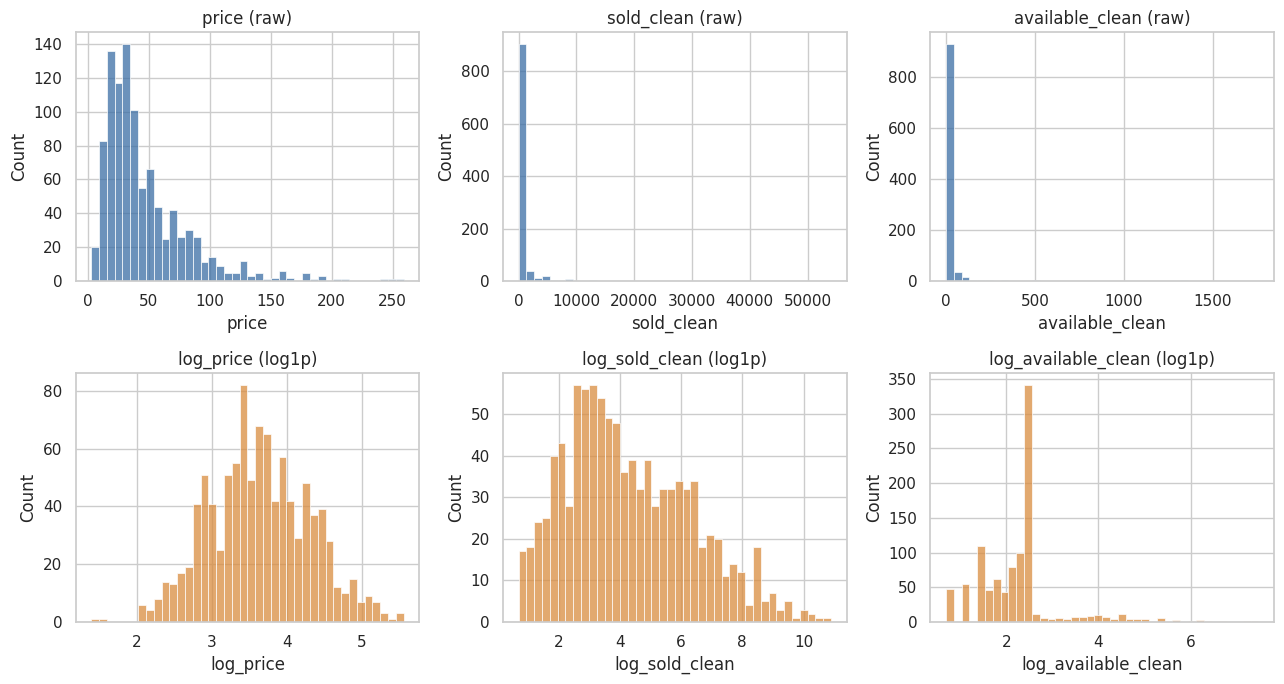

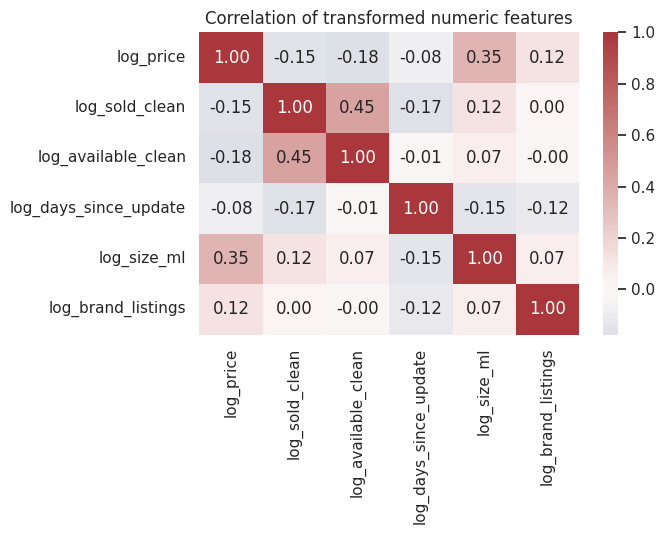

In [10]:
skew_cols = ["price", "sold_clean", "available_clean", "days_since_update",
             "size_ml", "brand_listings"]
results["skew_before"] = df[skew_cols].skew().round(2).to_dict()

# Log transform reduces right skew so extreme values do not dominate distances
for c in skew_cols:
    df["log_" + c] = np.log1p(df[c])
log_cols = ["log_" + c for c in skew_cols]
results["skew_after"] = df[log_cols].skew().round(2).to_dict()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), ["price", "sold_clean", "available_clean"]):
    sns.histplot(df[c], bins=40, ax=ax, color="#3b6ea5"); ax.set_title(f"{c} (raw)")
for ax, c in zip(axes[1], ["log_price", "log_sold_clean", "log_available_clean"]):
    sns.histplot(df[c], bins=40, ax=ax, color="#d98c3f"); ax.set_title(f"{c} (log1p)")
save("fig01_distributions.png")

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[log_cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation of transformed numeric features")
save("fig02_correlation.png")
results["corr"] = df[log_cols].corr().round(2).to_dict()

In [11]:
numeric_features = log_cols
categorical_features = ["category", "region"]
binary_features = ["is_set"]

X_cat = pd.get_dummies(df[categorical_features], dtype=float)
X_num = df[numeric_features].copy()
scaler = StandardScaler()
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=numeric_features)
X = pd.concat([X_num_scaled, X_cat.reset_index(drop=True),
               df[binary_features].reset_index(drop=True).astype(float)], axis=1)
X_values = X.values
print("Feature matrix:", X.shape)
print(list(X.columns))
results["n_features"] = X.shape[1]
results["feature_names"] = list(X.columns)

# Sensitivity of scaling choice (K Means, k = 4)
scaling_check = {}
base_labels = None
for name, sc in {"Standard": StandardScaler(), "MinMax": MinMaxScaler(),
                 "Robust": RobustScaler()}.items():
    Xs = np.hstack([sc.fit_transform(X_num), X_cat.values, df[binary_features].values])
    lab = KMeans(4, n_init=20, random_state=RANDOM_STATE).fit_predict(Xs)
    scaling_check[name] = {"silhouette": round(silhouette_score(Xs, lab), 3)}
    if name == "Standard":
        base_labels = lab
    else:
        scaling_check[name]["ARI_vs_Standard"] = round(adjusted_rand_score(base_labels, lab), 3)
print(scaling_check)
results["scaling_check"] = scaling_check

Feature matrix: (1000, 15)
['log_price', 'log_sold_clean', 'log_available_clean', 'log_days_since_update', 'log_size_ml', 'log_brand_listings', 'category_Body', 'category_Cologne', 'category_EDP', 'category_EDT', 'category_Generic', 'region_Asia', 'region_Other', 'region_US', 'is_set']
{'Standard': {'silhouette': np.float64(0.174)}, 'MinMax': {'silhouette': np.float64(0.489), 'ARI_vs_Standard': 0.029}, 'Robust': {'silhouette': np.float64(0.741), 'ARI_vs_Standard': 0.114}}


Components for 90% variance: 7


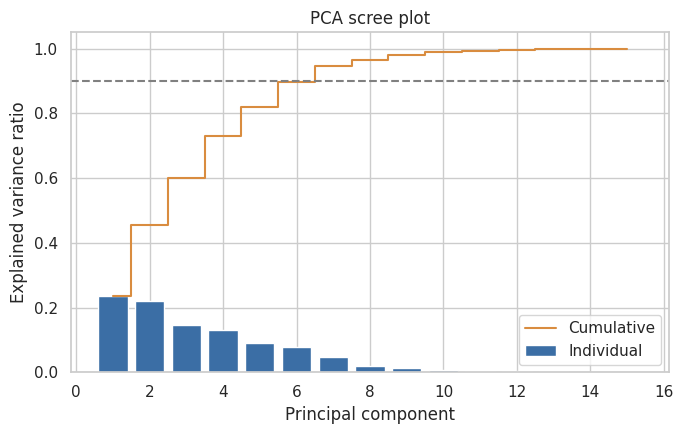

In [12]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_values)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum_var >= 0.90) + 1)
print("Components for 90% variance:", n90)
results["pca_components_90"] = n90
results["pca_var_first2"] = round(cum_var[1], 3)
results["pca_var_ratio"] = pca_full.explained_variance_ratio_[:5].round(3).tolist()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, color="#3b6ea5", label="Individual")
ax.step(range(1, len(cum_var) + 1), cum_var, where="mid", color="#d98c3f", label="Cumulative")
ax.axhline(0.90, ls="--", color="grey"); ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio"); ax.legend(); ax.set_title("PCA scree plot")
save("fig03_pca_scree.png")

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(X_values)
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=["PC1", "PC2"])
results["pca_loadings_top"] = {
    pc: loadings[pc].abs().sort_values(ascending=False).head(4).index.tolist()
    for pc in ["PC1", "PC2"]}

In [13]:
def evaluate(X_, labels):
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X_[mask], labels[mask]),
                davies_bouldin=davies_bouldin_score(X_[mask], labels[mask]),
                calinski_harabasz=calinski_harabasz_score(X_[mask], labels[mask]))

    silhouette  davies_bouldin  calinski_harabasz   inertia
k                                                          
2        0.148           2.060            178.553  5787.400
3        0.181           1.715            199.366  4873.685
4        0.174           1.693            197.331  4279.326
5        0.169           1.656            188.321  3883.073
6        0.169           1.584            182.875  3553.756
7        0.167           1.498            176.911  3297.730
8        0.162           1.507            166.515  3136.922
9        0.162           1.556            156.234  3017.319
10       0.152           1.643            147.219  2917.787


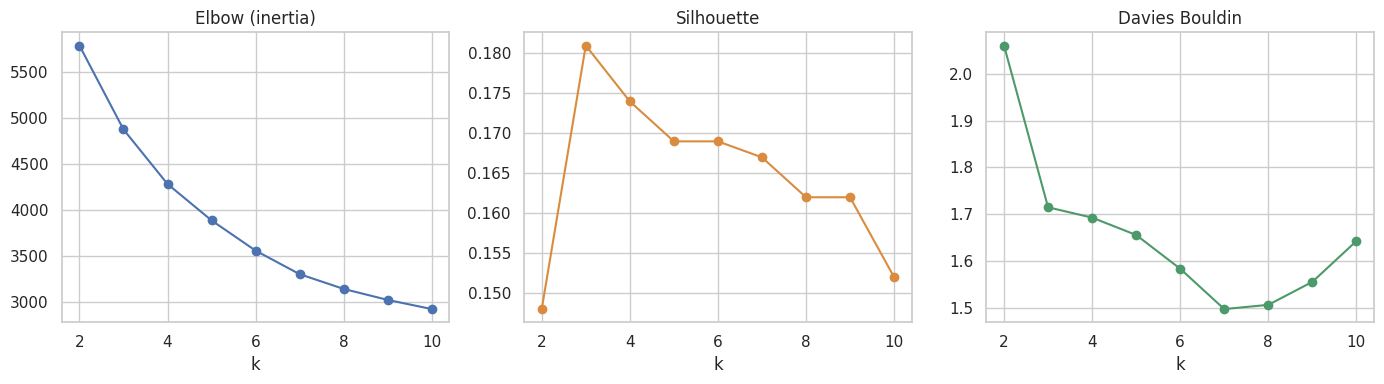

Selected k: 3


In [14]:
k_range = range(2, 11)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE).fit(X_values)
    m = evaluate(X_values, km.labels_); m.update(k=k, inertia=km.inertia_)
    km_rows.append(m)
km_table = pd.DataFrame(km_rows).set_index("k").round(3)
print(km_table)
results["kmeans_table"] = km_table.reset_index().to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(km_table.index, km_table["inertia"], "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_table.index, km_table["silhouette"], "o-", color="#d98c3f"); ax[1].set_title("Silhouette")
ax[2].plot(km_table.index, km_table["davies_bouldin"], "o-", color="#4c9a6a"); ax[2].set_title("Davies Bouldin")
for a in ax: a.set_xlabel("k")
save("fig04_kmeans_selection.png")

# Business rule: at least three segments so the result is actionable
cand = km_table.loc[3:8]
K_FINAL = int(cand["silhouette"].idxmax())
print("Selected k:", K_FINAL)
results["K_FINAL"] = K_FINAL

kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=50, random_state=RANDOM_STATE).fit(X_values)
df["km_label"] = kmeans.labels_

          silhouette  davies_bouldin  calinski_harabasz  cophenetic
ward           0.259           1.222            162.391       0.574
complete       0.139           1.860             98.724       0.478
average        0.374           0.773              8.502       0.712


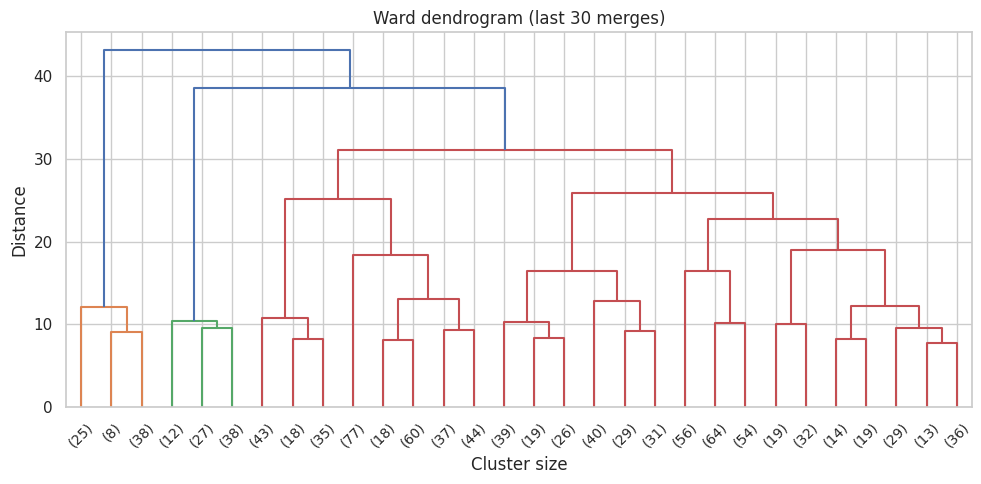

    silhouette  davies_bouldin  calinski_harabasz
k                                                
2        0.326           1.190            157.893
3        0.259           1.222            162.391
4        0.126           1.935            153.657
5        0.122           1.948            143.438
6        0.109           1.868            139.485
7        0.111           1.828            135.652
8        0.116           1.748            129.125
9        0.114           1.721            124.660
10       0.120           1.733            119.857


In [15]:
linkage_results = {}
for method in ["ward", "complete", "average"]:
    Z = linkage(X_values, method=method)
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method).fit_predict(X_values)
    coph, _ = cophenet(Z, pdist(X_values))
    row = evaluate(X_values, lab); row["cophenetic"] = coph
    linkage_results[method] = {k: round(float(v), 3) for k, v in row.items()}
print(pd.DataFrame(linkage_results).T)
results["linkage_results"] = linkage_results

Z_ward = linkage(X_values, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, color_threshold=Z_ward[-(K_FINAL - 1), 2])
plt.title("Ward dendrogram (last 30 merges)"); plt.xlabel("Cluster size"); plt.ylabel("Distance")
save("fig05_dendrogram.png")

hc_rows = []
for k in k_range:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_values)
    m = evaluate(X_values, lab); m["k"] = k; hc_rows.append(m)
hc_table = pd.DataFrame(hc_rows).set_index("k").round(3)
print(hc_table)
results["hc_table"] = hc_table.reset_index().to_dict("records")

hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit(X_values)
df["hc_label"] = hc.labels_

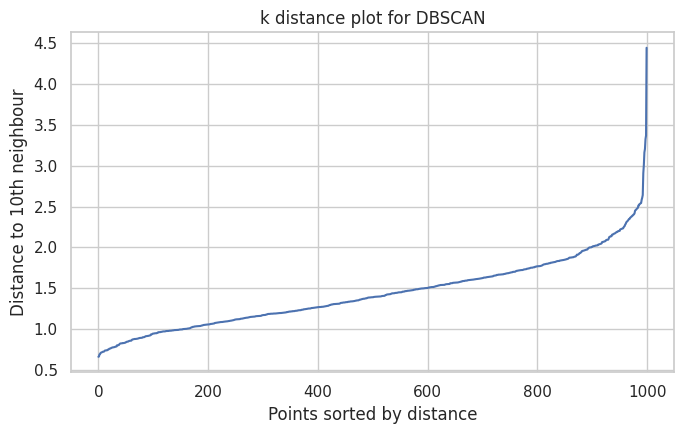

    eps  min_samples  clusters  noise_pct  silhouette
1   0.8           10         2       91.1    0.438296
17  1.6           10         2       13.3    0.414673
2   0.8           15         2       95.0    0.412592
22  1.8           15         2        7.8    0.400854
7   1.0           20         2       86.3    0.391560
27  2.0           20         2        4.1    0.379150
6   1.0           15         3       81.0    0.310512
10  1.2           15         3       57.0    0.158078
0   0.8            5        17       74.5    0.154106
11  1.2           20         4       65.4    0.130088
DBSCAN choice: 1.6 10


In [16]:
nn = NearestNeighbors(n_neighbors=10).fit(X_values)
dist, _ = nn.kneighbors(X_values)
plt.figure(figsize=(7, 4.5))
plt.plot(np.sort(dist[:, -1])); plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 10th neighbour"); plt.title("k distance plot for DBSCAN")
save("fig06_kdistance.png")

db_rows = []
for eps in np.arange(0.8, 4.01, 0.2):
    for ms in [5, 10, 15, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_values)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = float(np.mean(lab == -1))
        sil = evaluate(X_values, lab)["silhouette"] if n_cl >= 2 else np.nan
        db_rows.append(dict(eps=round(eps, 1), min_samples=ms, clusters=n_cl,
                            noise_pct=round(100 * noise, 1), silhouette=sil))
db_grid = pd.DataFrame(db_rows)
print(db_grid.sort_values("silhouette", ascending=False).head(10))
valid = db_grid[(db_grid.clusters >= 2) & (db_grid.noise_pct <= 15)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
EPS, MINS = float(best.eps), int(best.min_samples)
print("DBSCAN choice:", EPS, MINS)
results["dbscan_choice"] = dict(eps=EPS, min_samples=MINS)
results["dbscan_grid_top"] = db_grid.sort_values("silhouette", ascending=False).head(5).round(3).to_dict("records")
results["dbscan_grid_size"] = len(db_grid)
results["dbscan_valid_count"] = len(valid)

dbscan = DBSCAN(eps=EPS, min_samples=MINS).fit(X_values)
df["db_label"] = dbscan.labels_
results["dbscan_noise_pct"] = round(100 * float(np.mean(dbscan.labels_ == -1)), 1)
results["dbscan_clusters"] = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
results["dbscan_sizes"] = pd.Series(dbscan.labels_).value_counts().to_dict()

In [17]:
comparison = pd.DataFrame({
    "K Means": evaluate(X_values, df["km_label"].values),
    "Hierarchical (Ward)": evaluate(X_values, df["hc_label"].values),
    "DBSCAN": evaluate(X_values, df["db_label"].values)}).T
comparison["clusters"] = [df["km_label"].nunique(), df["hc_label"].nunique(),
                          results["dbscan_clusters"]]
comparison["noise_pct"] = [0, 0, results["dbscan_noise_pct"]]
comparison = comparison.round(3)
print(comparison)
results["comparison"] = comparison.reset_index().to_dict("records")
results["ARI_km_hc"] = round(adjusted_rand_score(df["km_label"], df["hc_label"]), 3)

# Stability: agreement between full model labels and models refitted on 80% subsamples
rng = np.random.RandomState(RANDOM_STATE)
stab = {"K Means": [], "Hierarchical (Ward)": []}
for _ in range(30):
    idx = rng.choice(len(X_values), int(0.8 * len(X_values)), replace=False)
    km_s = KMeans(K_FINAL, n_init=10, random_state=int(rng.randint(1e6))).fit_predict(X_values[idx])
    hc_s = AgglomerativeClustering(K_FINAL, linkage="ward").fit_predict(X_values[idx])
    stab["K Means"].append(adjusted_rand_score(df["km_label"].values[idx], km_s))
    stab["Hierarchical (Ward)"].append(adjusted_rand_score(df["hc_label"].values[idx], hc_s))
results["stability_ARI"] = {k: [round(float(np.mean(v)), 3), round(float(np.std(v)), 3)]
                            for k, v in stab.items()}
print(results["stability_ARI"])

                     silhouette  davies_bouldin  calinski_harabasz  clusters  \
K Means                   0.181           1.715            199.366         3   
Hierarchical (Ward)       0.259           1.222            162.391         3   
DBSCAN                    0.415           0.764             80.091         2   

                     noise_pct  
K Means                    0.0  
Hierarchical (Ward)        0.0  
DBSCAN                    13.3  
{'K Means': [0.932, 0.109], 'Hierarchical (Ward)': [0.657, 0.293]}


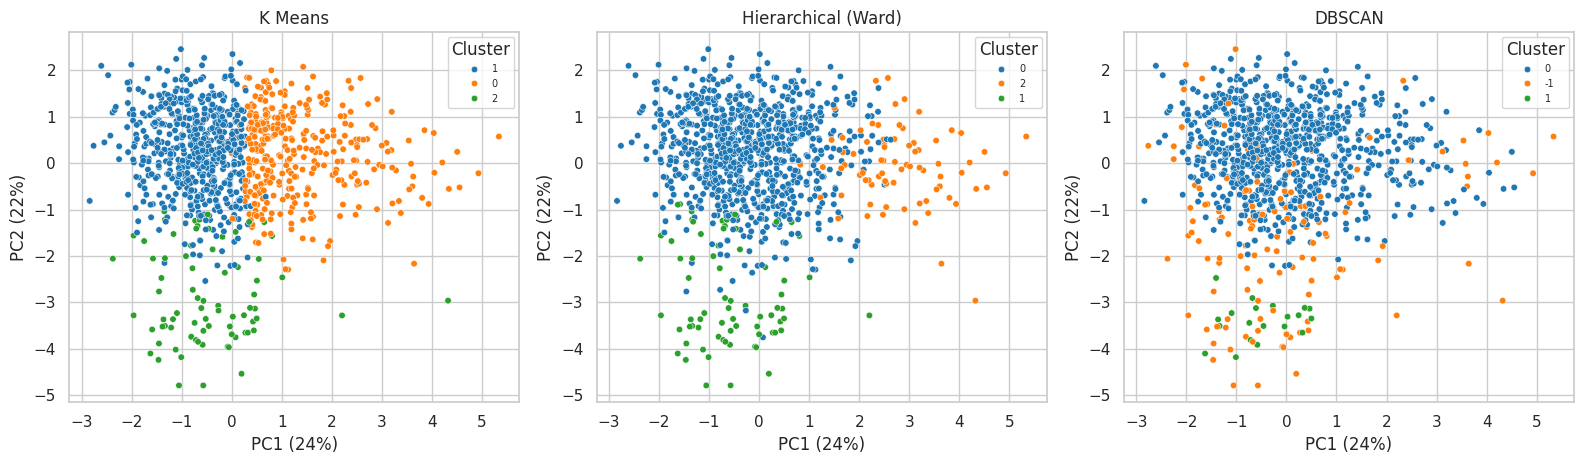

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, col) in zip(axes, [("K Means", "km_label"), ("Hierarchical (Ward)", "hc_label"),
                                  ("DBSCAN", "db_label")]):
    sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=df[col].astype(str), palette="tab10",
                    s=22, ax=ax, legend="full")
    ax.set_title(name); ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
    ax.legend(title="Cluster", fontsize=7, loc="best")
save("fig07_pca_clusters.png")

segment
Premium slow movers        582
Volume bestsellers         341
Miniatures and samplers     77
Name: count, dtype: int64
segment                   Volume bestsellers  Premium slow movers  \
listings                              341.00               582.00   
median_price                           29.99                44.99   
median_sold                           550.00                20.00   
total_sold                         705876.00             26885.00   
median_stock                           10.00                 6.00   
median_size_ml                        100.55               100.55   
median_days_since_update                0.89                 1.76   
total_revenue                    23753451.32           1785157.90   
share_us                                0.99                 0.86   
share_set                               0.03                 0.02   
share_listings_pct                     34.10                58.20   
share_revenue_pct                      91.90 

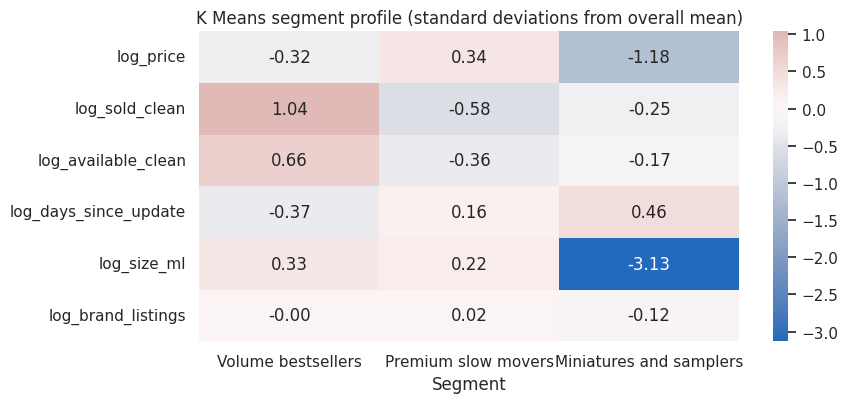

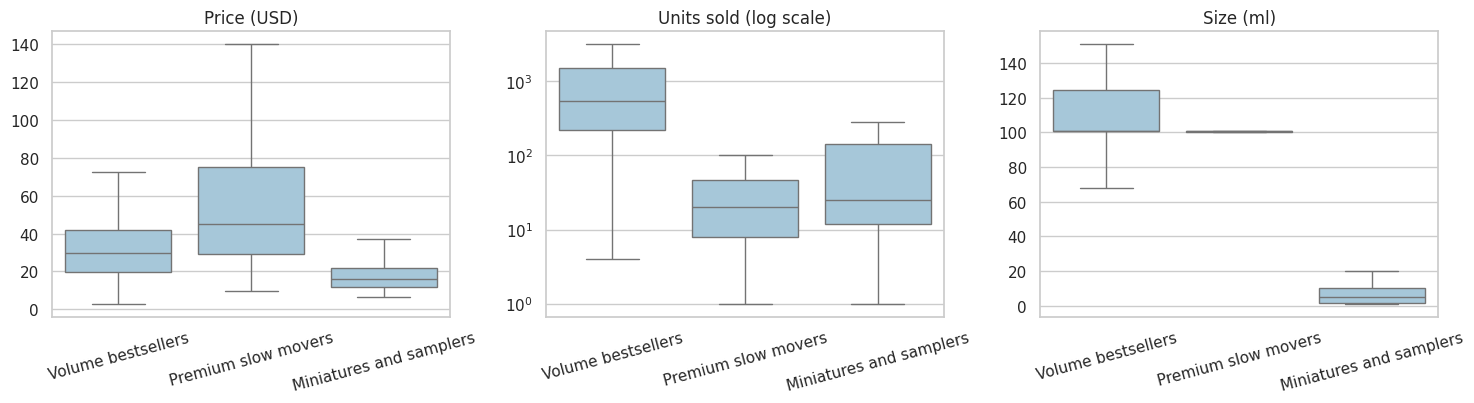

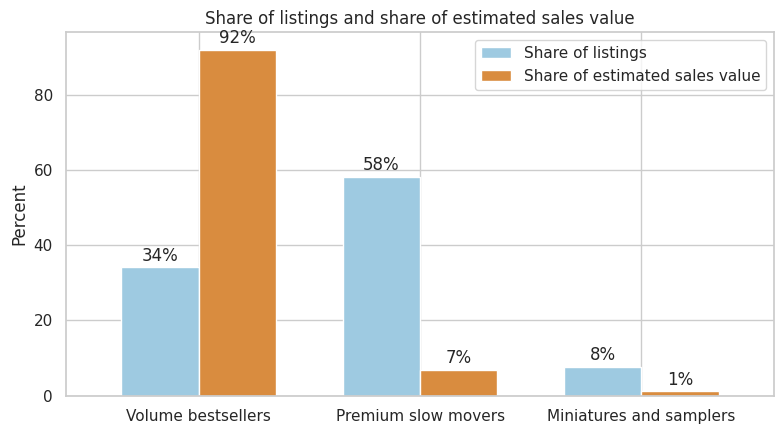

In [19]:
med = df.groupby("km_label").agg(sold=("sold_clean", "median"), size=("size_ml", "median"))
bestsellers = med["sold"].idxmax()                       # highest median units sold
miniatures = med["size"].idxmin()                        # smallest median size
premium = [c for c in med.index if c not in (bestsellers, miniatures)][0]
df["segment"] = df["km_label"].map({bestsellers: "Volume bestsellers",
                                    premium: "Premium slow movers",
                                    miniatures: "Miniatures and samplers"})
order = ["Volume bestsellers", "Premium slow movers", "Miniatures and samplers"]
print(df["segment"].value_counts())

profile = df.groupby("segment").agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_sold=("sold_clean", "median"),
    total_sold=("sold_clean", "sum"),
    median_stock=("available_clean", "median"),
    median_size_ml=("size_ml", "median"),
    median_days_since_update=("days_since_update", "median"),
    total_revenue=("est_revenue", "sum"),
    share_us=("region", lambda s: (s == "US").mean()),
    share_set=("is_set", "mean")).round(2).loc[order]
profile["share_listings_pct"] = (100 * profile["listings"] / len(df)).round(1)
profile["share_revenue_pct"] = (100 * profile["total_revenue"] / profile["total_revenue"].sum()).round(1)
cat_mix = pd.crosstab(df["segment"], df["category"], normalize="index").round(2).loc[order]
print(profile.T); print(cat_mix)
results["profile"] = profile.reset_index().to_dict("records")
results["cat_mix"] = cat_mix.reset_index().to_dict("records")
results["top_brands"] = {c: g["brand"].value_counts().head(4).to_dict()
                         for c, g in df.groupby("segment")}

z = df.groupby("segment")[numeric_features].mean().loc[order]
z = (z - df[numeric_features].mean()) / df[numeric_features].std()
plt.figure(figsize=(9, 4.2))
sns.heatmap(z.T, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("K Means segment profile (standard deviations from overall mean)")
plt.xlabel("Segment")
save("fig08_cluster_profile.png")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c, t in zip(axes, ["price", "sold_clean", "size_ml"],
                    ["Price (USD)", "Units sold (log scale)", "Size (ml)"]):
    sns.boxplot(data=df, x="segment", y=c, order=order, ax=ax, color="#9ecae1", showfliers=False)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=15)
    if c == "sold_clean": ax.set_yscale("log")
save("fig09_cluster_boxplots.png")

# Executive summary chart: share of listings against share of estimated sales value
share = pd.DataFrame({
    "Share of listings": df["segment"].value_counts(normalize=True) * 100,
    "Share of estimated sales value":
        df.groupby("segment")["est_revenue"].sum() / df["est_revenue"].sum() * 100}).loc[order]
ax = share.plot(kind="bar", figsize=(8, 4.5), color=["#9ecae1", "#d98c3f"], width=0.7)
ax.set_ylabel("Percent"); ax.set_xlabel("")
ax.set_title("Share of listings and share of estimated sales value")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=2)
save("fig10_exec_summary.png")

In [20]:
sil_samples = silhouette_samples(X_values, df["km_label"].values)
df["silhouette"] = sil_samples
sil_seg = df.groupby("segment")["silhouette"].agg(
    mean="mean", share_negative=lambda s: (s < 0).mean(),
    share_below_025=lambda s: (s < 0.25).mean()).loc[order].round(3)
print(sil_seg)
print("Overall share with negative silhouette:", round((sil_samples < 0).mean(), 3))
results["silhouette_by_segment"] = sil_seg.reset_index().to_dict("records")
results["silhouette_negative_share"] = round(float((sil_samples < 0).mean()), 3)

                          mean  share_negative  share_below_025
segment                                                        
Volume bestsellers       0.167           0.006            0.739
Premium slow movers      0.173           0.010            0.796
Miniatures and samplers  0.302           0.026            0.364
Overall share with negative silhouette: 0.01


In [21]:
def refit_without(mask_remove, label):
    keep = ~mask_remove
    ref = KMeans(K_FINAL, init="k-means++", n_init=50,
                 random_state=RANDOM_STATE).fit(X_values[keep])
    ari = adjusted_rand_score(df.loc[keep, "km_label"].values, ref.labels_)
    print(f"{label}: removed {mask_remove.sum()}, ARI = {ari:.3f}")
    print(pd.crosstab(df.loc[keep, "km_label"].values, ref.labels_,
                      rownames=["full model"], colnames=["refit"]))
    return ari

all_flag = df["extreme_flag"].values == 1                 # any variable, including size
ari_all = refit_without(all_flag, "All flagged rows")
com_cols = ["price", "sold_clean", "available_clean", "days_since_update"]
logs_c = np.log1p(df[com_cols])
z_c = (logs_c - logs_c.mean()) / logs_c.std()
com_flag = (z_c.abs() > 3).any(axis=1).values            # commercial variables only
ari_com = refit_without(com_flag, "Commercial variables only")
results["outlier_sensitivity"] = {"all_flagged": round(ari_all, 3),
                                  "commercial_only": round(ari_com, 3),
                                  "n_all": int(all_flag.sum()), "n_com": int(com_flag.sum())}

All flagged rows: removed 70, ARI = 0.345
refit         0    1    2
full model               
0            44   40  233
1           302  275    3
2            12   18    3
Commercial variables only: removed 28, ARI = 0.850
refit         0   1    2
full model              
0           317   0    0
1            41   0  539
2             0  75    0


In [22]:
def top_segment_stats(Xm, lab, frame):
    """Cluster with the highest median units sold: its share of listings and of sales value."""
    d = frame.assign(lab=lab)
    top = d.groupby("lab")["sold_clean"].median().idxmax()
    sel = d[d["lab"] == top]
    return len(sel) / len(d), sel["est_revenue"].sum() / d["est_revenue"].sum()

def scenario(name, Xm, frame, base_labels_on_rows):
    lab = KMeans(K_FINAL, init="k-means++", n_init=50, random_state=RANDOM_STATE).fit_predict(Xm)
    m = evaluate(Xm, lab)
    sh_l, sh_r = top_segment_stats(Xm, lab, frame)
    return {"scenario": name, "rows": len(frame),
            "silhouette": round(m["silhouette"], 3),
            "davies_bouldin": round(m["davies_bouldin"], 3),
            "calinski_harabasz": round(m["calinski_harabasz"], 1),
            "ARI_vs_selected": round(adjusted_rand_score(base_labels_on_rows, lab), 3),
            "top_share_listings": round(100 * sh_l, 1),
            "top_share_value": round(100 * sh_r, 1)}

other = np.hstack([X_cat.values, df[binary_features].values])
base = df["km_label"].values
rows16 = []
# (a) no treatment: raw values, standardised only
Xa = np.hstack([StandardScaler().fit_transform(df[skew_cols]), other])
rows16.append(scenario("No treatment (raw, standardised)", Xa, df, base))
# (b) selected: log transform then standardise
rows16.append(scenario("Log transform (selected)", X_values, df, base))
# (c) log, then cap at the 1st and 99th percentiles
capped = df[log_cols].clip(df[log_cols].quantile(0.01), df[log_cols].quantile(0.99), axis=1)
Xc = np.hstack([StandardScaler().fit_transform(capped), other])
rows16.append(scenario("Log transform and capping", Xc, df, base))
# (d) log, remove listings extreme on commercial variables
keep = ~com_flag
rows16.append(scenario("Log, commercial extremes removed", X_values[keep], df[keep], base[keep]))
# (e) log, remove every flagged listing
keep = ~all_flag
rows16.append(scenario("Log, all flagged listings removed", X_values[keep], df[keep], base[keep]))
before_after = pd.DataFrame(rows16)
print(before_after.to_string(index=False))
results["before_after"] = rows16

                         scenario  rows  silhouette  davies_bouldin  calinski_harabasz  ARI_vs_selected  top_share_listings  top_share_value
 No treatment (raw, standardised)  1000       0.220           1.190              161.8           -0.024                 0.2              0.0
         Log transform (selected)  1000       0.181           1.715              199.4            1.000                34.1             91.9
        Log transform and capping  1000       0.181           1.709              201.8            0.993                34.1             91.9
 Log, commercial extremes removed   972       0.169           1.782              193.5            0.850                36.8             91.7
Log, all flagged listings removed   930       0.149           1.943              168.0            0.345                25.7             88.5


In [23]:
n_any = int((df["n_imputed"] > 0).sum())
imp_share = (df.assign(imp=df["n_imputed"] > 0).groupby("segment")["imp"].mean().loc[order]).round(3)
print("Listings with at least one imputed value:", n_any)
print("Share imputed by segment:\n", imp_share)

def matrix_from(num_df):
    """Log transform, standardise, then add the encoded and binary columns."""
    logs = np.log1p(num_df[skew_cols])
    return np.hstack([StandardScaler().fit_transform(logs), other])

def variant(name, Xm, rows=None):
    lab = KMeans(K_FINAL, init="k-means++", n_init=50, random_state=RANDOM_STATE).fit_predict(Xm)
    ref = base if rows is None else base[rows]
    return {"variant": name, "rows": len(Xm),
            "silhouette": round(silhouette_score(Xm, lab), 3),
            "ARI_vs_selected": round(adjusted_rand_score(ref, lab), 3),
            "sizes": sorted(np.bincount(lab).tolist(), reverse=True)}

raw_full = raw_num.copy(); raw_full["brand_listings"] = df["brand_listings"]
imp_rows = [variant("Median imputation (selected)", X_values)]
mean_df = raw_full.fillna(raw_full.mean())
imp_rows.append(variant("Mean imputation", matrix_from(mean_df)))
# KNN imputation in the standardised log space, using category and region as neighbours too
logs_knn = np.log1p(raw_full[skew_cols])
sc_knn = StandardScaler().fit(logs_knn)                  # scaler ignores missing values
Z_knn = np.hstack([sc_knn.transform(logs_knn), other])
Z_imp = KNNImputer(n_neighbors=5).fit_transform(Z_knn)
imp_rows.append(variant("KNN imputation (5 neighbours)", Z_imp))
cc = (df["n_imputed"] == 0).values                       # complete cases only
imp_rows.append(variant("Complete cases only", X_values[cc], rows=cc))
imputation_table = pd.DataFrame(imp_rows)
print(imputation_table.to_string(index=False))
results["imputation"] = imp_rows
results["imputed_any"] = n_any
results["imputed_share_by_segment"] = imp_share.to_dict()

Listings with at least one imputed value: 184
Share imputed by segment:
 segment
Volume bestsellers         0.235
Premium slow movers        0.156
Miniatures and samplers    0.169
Name: imp, dtype: float64
                      variant  rows  silhouette  ARI_vs_selected           sizes
 Median imputation (selected)  1000       0.181            1.000  [582, 341, 77]
              Mean imputation  1000       0.190            0.862  [591, 333, 76]
KNN imputation (5 neighbours)  1000       0.193            0.874 [595, 304, 101]
          Complete cases only   816       0.240            0.542  [609, 144, 63]


In [24]:
cat5 = pd.get_dummies(df[["category", "region"]], dtype=float).values
labels_raw = df["category_raw"].fillna("Missing").str.strip().str.lower()
keep_lab = labels_raw.value_counts()[lambda s: s >= 15].index
fine = pd.get_dummies(labels_raw.where(labels_raw.isin(keep_lab), "other"), dtype=float).values
coarse = df["category"].where(df["category"].isin(["EDT", "EDP"]), "Other")
coarse = pd.get_dummies(coarse, dtype=float).values
reg = pd.get_dummies(df["region"], dtype=float).values
num_std = X_num_scaled.values; is_set = df[binary_features].values

def grouping(name, cat_block):
    Xm = np.hstack([num_std, cat_block, is_set])
    return variant(name, Xm)

cat_rows = [grouping("Five groups and region (selected)", cat5),
            grouping("Three groups (EDT, EDP, other) and region", np.hstack([coarse, reg])),
            grouping(f"Finer groups ({fine.shape[1]} raw labels) and region", np.hstack([fine, reg])),
            grouping("Category removed, region kept", reg),
            grouping("Region removed, category kept",
                     pd.get_dummies(df["category"], dtype=float).values)]
category_table = pd.DataFrame(cat_rows)
print(category_table.to_string(index=False))
results["category_grouping"] = cat_rows

                                  variant  rows  silhouette  ARI_vs_selected          sizes
        Five groups and region (selected)  1000       0.181            1.000 [582, 341, 77]
Three groups (EDT, EDP, other) and region  1000       0.181            0.989 [585, 338, 77]
   Finer groups (7 raw labels) and region  1000       0.179            0.963 [592, 331, 77]
            Category removed, region kept  1000       0.199            0.952 [587, 336, 77]
            Region removed, category kept  1000       0.187            0.996 [583, 340, 77]


In [25]:
def scaled_matrix(sc):
    return np.hstack([sc.fit_transform(X_num), X_cat.values, df[binary_features].values])

scale_rows = []
for name, sc in {"Standard": StandardScaler(), "MinMax": MinMaxScaler(),
                 "Robust": RobustScaler()}.items():
    Xs = scaled_matrix(sc)
    km_l = KMeans(K_FINAL, init="k-means++", n_init=50, random_state=RANDOM_STATE).fit_predict(Xs)
    hc_l = AgglomerativeClustering(K_FINAL, linkage="ward").fit_predict(Xs)
    # stability of each model on 30 subsamples of 80 percent
    rng = np.random.RandomState(RANDOM_STATE); st_km, st_hc = [], []
    for _ in range(30):
        idx = rng.choice(len(Xs), int(0.8 * len(Xs)), replace=False)
        st_km.append(adjusted_rand_score(km_l[idx], KMeans(K_FINAL, n_init=10,
                     random_state=int(rng.randint(1e6))).fit_predict(Xs[idx])))
        st_hc.append(adjusted_rand_score(hc_l[idx],
                     AgglomerativeClustering(K_FINAL, linkage="ward").fit_predict(Xs[idx])))
    var = Xs.var(axis=0)
    mk, mh = evaluate(Xs, km_l), evaluate(Xs, hc_l)
    sh_l, sh_r = top_segment_stats(Xs, km_l, df)
    scale_rows.append({"scaler": name,
        "km_silhouette": round(mk["silhouette"], 3), "hc_silhouette": round(mh["silhouette"], 3),
        "km_davies_bouldin": round(mk["davies_bouldin"], 3), "hc_davies_bouldin": round(mh["davies_bouldin"], 3),
        "km_stability": round(float(np.mean(st_km)), 3), "hc_stability": round(float(np.mean(st_hc)), 3),
        "ARI_km_vs_selected": round(adjusted_rand_score(base, km_l), 3),
        "ARI_km_vs_hc": round(adjusted_rand_score(km_l, hc_l), 3),
        "numeric_variance_share": round(float(var[:len(numeric_features)].sum() / var.sum()), 3),
        "top_share_listings": round(100 * sh_l, 1), "top_share_value": round(100 * sh_r, 1)})
scaling_table = pd.DataFrame(scale_rows)
print(scaling_table.T)
results["scaling_models"] = scale_rows

                               0       1       2
scaler                  Standard  MinMax  Robust
km_silhouette              0.181   0.462   0.781
hc_silhouette              0.259   0.436   0.759
km_davies_bouldin          1.715   1.279    0.46
hc_davies_bouldin          1.222   1.612   0.361
km_stability               0.932     1.0   0.965
hc_stability               0.657   0.991     1.0
ARI_km_vs_selected           1.0   0.035   0.195
ARI_km_vs_hc               0.294   0.809   0.993
numeric_variance_share     0.879   0.228     1.0
top_share_listings          34.1    46.3    86.2
top_share_value             91.9    75.4    97.9


In [26]:
df.to_csv("sales_clustered.csv", index=False)
with open("results.json", "w") as f:
    json.dump(results, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))